# 01 – Environment check & data preparation

**Project:** *Forecasting Football Player Market Values from Public Transfermarkt Data: A Time-Aware, Explainable Machine Learning Study*

**What this notebook does**
- Checks that the `football` conda environment works (packages, Apple-GPU / MPS).
- Reads the Kaggle *Football Data from Transfermarkt* (davidcariboo) CSVs **directly from the zip file** – nothing is unzipped, so no extra disk is used.
- Keeps **only the columns we need** and stores them with **small data types** (`int8/int16/int32/float32/category`).
- Saves each table as a compressed **Parquet** file in `data/processed/`.
- Runs first sanity checks that matter for the next step (date ranges, *data-leakage* risks).

**Not used:** `game_lineups.csv` and `game_events.csv` (they stay inside the zip, untouched).

In [1]:
import sys, zipfile, warnings
from pathlib import Path

ROOT = Path.cwd().resolve().parent if Path.cwd().name == "notebooks" else Path.cwd().resolve()
sys.path.insert(0, str(ROOT))
from src.config import RAW_ZIP, PROCESSED, RESULTS, SEED, set_seed, savefig, apply_plot_style, PALETTE

warnings.filterwarnings("ignore", message="IProgress not found")
import numpy as np, pandas as pd, matplotlib.pyplot as plt
import pyarrow, sklearn, xgboost, lightgbm, catboost, shap, torch

set_seed(SEED)
apply_plot_style()
warnings.filterwarnings("ignore", category=FutureWarning)

print("Python ", sys.version.split()[0])
for m in (pd, np, pyarrow, sklearn, xgboost, lightgbm, catboost, shap, torch):
    print(f"{m.__name__:12s}{m.__version__}")
print("PyTorch MPS (Apple GPU) available:", torch.backends.mps.is_available())
print("Raw data zip:", RAW_ZIP.name, f"({RAW_ZIP.stat().st_size/1e6:.0f} MB)")

Python  3.11.17
pandas      3.0.6
numpy       1.26.4
pyarrow     25.0.0
sklearn     1.9.1
xgboost     3.4.2
lightgbm    4.7.0
catboost    1.2.7
shap        0.48.0
torch       2.14.1
PyTorch MPS (Apple GPU) available: True
Raw data zip: transfermarkt_davidcariboo.zip (246 MB)


## 1. Which columns we keep (and why)

Each table gets a small *spec*: `column → type`.
- `int8/int16/int32` for counts and IDs (if a column has missing values it becomes `float32`, because plain integers cannot hold "missing").
- `category` for repeated text (position, foot, league code…) – stored once, referenced by a small number.
- `date` columns become real datetimes.

**Dropped on purpose:** names/URLs/images (not needed), and *snapshot* columns that describe the player **today** rather than at the valuation date
(e.g. `highest_market_value_in_eur`, the club's current `total_market_value`, `player_current_club_id`). Using them would leak future information into the model.

In [2]:
SPECS = {
    "players": {
        "player_id": "int32", "name": "str", "date_of_birth": "date",
        "position": "category", "sub_position": "category", "foot": "category",
        "height_in_cm": "float32", "country_of_citizenship": "category",
        # snapshot columns (value as of the 2026 scrape) – kept ONLY for the leakage check below
        "contract_expiration_date": "date", "international_caps": "float32",
        "current_club_id": "int32", "last_season": "int16",
    },
    "player_valuations": {
        "player_id": "int32", "date": "date", "market_value_in_eur": "int32",
        "current_club_id": "int32", "player_club_domestic_competition_id": "category",
    },
    "appearances": {
        "game_id": "int32", "player_id": "int32", "player_club_id": "int32", "date": "date",
        "competition_id": "category", "yellow_cards": "int8", "red_cards": "int8",
        "goals": "int8", "assists": "int8", "minutes_played": "int16",
    },
    "transfers": {
        "player_id": "int32", "transfer_date": "date", "transfer_season": "category",
        "from_club_id": "int32", "to_club_id": "int32",
        "transfer_fee": "float32", "market_value_in_eur": "float32",
    },
    "clubs": {
        "club_id": "int32", "club_code": "str", "name": "str",
        "domestic_competition_id": "category", "last_season": "int16",
    },
    "competitions": {
        "competition_id": "category", "name": "str", "sub_type": "category", "type": "category",
        "country_id": "int32", "country_name": "category", "domestic_league_code": "category",
        "confederation": "category",
    },
    "games": {
        "game_id": "int32", "competition_id": "category", "season": "int16", "date": "date",
        "home_club_id": "int32", "away_club_id": "int32",
        "home_club_goals": "int8", "away_club_goals": "int8",
        "home_club_position": "float32", "away_club_position": "float32",
        "competition_type": "category",
    },
    "club_games": {
        "game_id": "int32", "club_id": "int32", "own_goals": "int8", "own_position": "float32",
        "opponent_id": "int32", "opponent_goals": "int8", "hosting": "category", "is_win": "int8",
    },
    "countries": {
        "country_id": "int32", "country_name": "str", "country_code": "str", "confederation": "category",
    },
    "national_teams": {
        "national_team_id": "int32", "name": "str", "country_id": "int32", "confederation": "category",
    },
}

## 2. Convert CSV (inside the zip) → Parquet

`cast()` applies the spec and **checks that numbers fit** in the small type (so nothing silently overflows).

In [3]:
def cast(df: pd.DataFrame, spec: dict) -> pd.DataFrame:
    for col, kind in spec.items():
        s = df[col]
        if kind == "date":
            df[col] = pd.to_datetime(s, errors="coerce")
        elif kind == "category":
            df[col] = s.astype("category")
        elif kind == "str":
            df[col] = s.astype("string")
        elif kind == "float32":
            df[col] = pd.to_numeric(s, errors="coerce").astype("float32")
        elif kind.startswith("int"):
            s = pd.to_numeric(s, errors="coerce")
            lo, hi = np.iinfo(kind).min, np.iinfo(kind).max
            assert s.dropna().between(lo, hi).all(), f"{col}: values do not fit in {kind}"
            df[col] = s.astype(kind) if s.notna().all() else s.astype("float32")
    return df


rows = []
with zipfile.ZipFile(RAW_ZIP) as zf:
    for table, spec in SPECS.items():
        info = zf.getinfo(f"{table}.csv")
        with zf.open(info) as fh:
            header = pd.read_csv(fh, nrows=0).columns
        with zf.open(info) as fh:
            df = pd.read_csv(fh, usecols=list(spec), low_memory=False)
        df = cast(df[list(spec)], spec)
        path = PROCESSED / f"{table}.parquet"
        df.to_parquet(path, compression="zstd", index=False)
        rows.append({
            "table": table, "rows": len(df),
            "cols_kept": df.shape[1], "cols_in_csv": len(header),
            "csv_MB": round(info.file_size / 1e6, 1),
            "parquet_MB": round(path.stat().st_size / 1e6, 1),
            "RAM_MB": round(df.memory_usage(deep=True).sum() / 1e6, 1),
        })
        print(f"{table:18s} {len(df):>9,} rows  →  {path.name}")
        del df

overview = pd.DataFrame(rows)
total = overview.drop(columns="table").sum().to_dict() | {"table": "TOTAL"}
overview = pd.concat([overview, pd.DataFrame([total])], ignore_index=True)
overview = overview.astype({"rows": int, "cols_kept": int, "cols_in_csv": int}).round(1)
overview.to_csv(RESULTS / "table01_raw_tables_overview.csv", index=False)
overview

players               50,149 rows  →  players.parquet


player_valuations    656,301 rows  →  player_valuations.parquet


appearances        1,894,350 rows  →  appearances.parquet


transfers            175,165 rows  →  transfers.parquet
clubs                    796 rows  →  clubs.parquet
competitions              65 rows  →  competitions.parquet


games                 88,958 rows  →  games.parquet
club_games           177,916 rows  →  club_games.parquet
countries                124 rows  →  countries.parquet
national_teams           124 rows  →  national_teams.parquet


,table,rows,cols_kept,cols_in_csv,csv_MB,parquet_MB,RAM_MB
0,players,50149,12,26,19.6,1.2,3.1
1,player_valuations,656301,5,6,39.6,3.4,13.8
2,appearances,1894350,10,13,198.4,7.8,51.1
3,transfers,175165,7,10,18.1,1.3,5.1
4,clubs,796,5,17,0.2,0.0,0.0
5,competitions,65,8,11,0.0,0.0,0.0
6,games,88958,11,23,29.0,1.0,3.0
7,club_games,177916,8,11,14.7,1.4,3.6
8,countries,124,4,8,0.0,0.0,0.0
9,national_teams,124,4,17,0.0,0.0,0.0


## 3. Load back & sanity checks

From now on every notebook reads these small Parquet files – never the CSVs.

In [4]:
load = lambda t, cols=None: pd.read_parquet(PROCESSED / f"{t}.parquet", columns=cols)

players = load("players")
vals = load("player_valuations")
apps = load("appearances")
transfers = load("transfers")
comps = load("competitions")

def rng(s): return f"{s.min():%Y-%m-%d} → {s.max():%Y-%m-%d}"
print("Valuations :", rng(vals["date"]), f"| {vals.player_id.nunique():,} players")
print("Appearances:", rng(apps["date"]),  f"| {apps.player_id.nunique():,} players")
print("Transfers  :", rng(transfers["transfer_date"]))
print("Valuations with value ≤ 0 or missing:", int((vals.market_value_in_eur.fillna(0) <= 0).sum()))
print("Domestic leagues in valuations:", vals.player_club_domestic_competition_id.nunique())

Valuations : 2000-01-20 → 2026-06-12 | 41,528 players
Appearances: 2012-07-03 → 2026-06-28 | 29,531 players
Transfers  : 1993-07-01 → 2030-06-30
Valuations with value ≤ 0 or missing: 1
Domestic leagues in valuations: 32


### 3a. Valuations per year

How much history do we have, and how did typical values change over time? (Two separate panels, not two y-axes.)
Years with fewer than 1,000 valuations (2000–2003: only 1–2 rows each) are left out of the plot because their median is meaningless. 2026 covers January–June only.

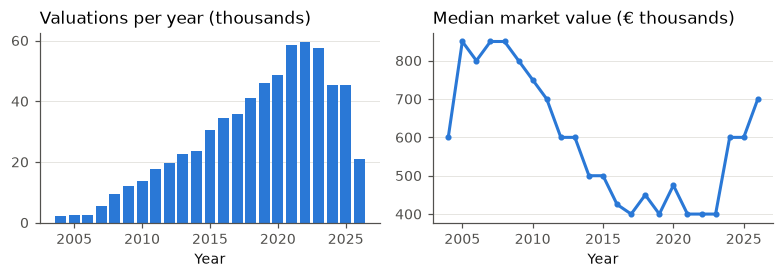

year,2004,2005,2006,2007,2008,2009,2010,2011,2012,2013,...,2017,2018,2019,2020,2021,2022,2023,2024,2025,2026
n,2305.0,2439.0,2673.0,5617.0,9305.0,12067.0,13795.0,17788.0,19714.0,22636.0,...,35923.0,41097.0,46088.0,48749.0,58412.0,59564.0,57576.0,45376.0,45482.0,20852.0
median,600000.0,850000.0,800000.0,850000.0,850000.0,800000.0,750000.0,700000.0,600000.0,600000.0,...,400000.0,450000.0,400000.0,475000.0,400000.0,400000.0,400000.0,600000.0,600000.0,700000.0


In [5]:
by_year = (vals.assign(year=vals["date"].dt.year)
               .groupby("year")["market_value_in_eur"]
               .agg(n="size", median="median"))
by_year = by_year[by_year["n"] >= 1000]

fig, axes = plt.subplots(1, 2, figsize=(7.2, 2.6))
axes[0].bar(by_year.index, by_year["n"] / 1e3, width=0.8, color=PALETTE[0])
axes[0].set_title("Valuations per year (thousands)", loc="left")
axes[1].plot(by_year.index, by_year["median"] / 1e3, color=PALETTE[0], marker="o", markersize=3)
axes[1].set_title("Median market value (€ thousands)", loc="left")
for ax in axes:
    ax.set_xlabel("Year")
fig.tight_layout()
savefig(fig, "fig01_valuations_per_year")
plt.show()
by_year.T

### 3b. Leakage check – `contract_expiration_date` and `international_caps`

Both columns in `players.csv` are **snapshots taken at scrape time (2026)**, not values at the valuation date *t*.
- **Contract date:** it is the player's *current* contract. For a valuation in, say, 2018 that contract was often signed years later → future information.
  Also, missing contract dates mostly belong to retired / inactive players → "missing" itself hints at the player's future.
- **International caps:** a running total up to 2026 → includes caps earned **after** *t* (a player who later becomes a star has many caps).

In [6]:
active = players["last_season"] >= 2025
check = pd.DataFrame({
    "contract date known (%)": [players.loc[active, "contract_expiration_date"].notna().mean() * 100,
                                players.loc[~active, "contract_expiration_date"].notna().mean() * 100],
    "caps known (%)": [players.loc[active, "international_caps"].notna().mean() * 100,
                       players.loc[~active, "international_caps"].notna().mean() * 100],
}, index=["active (last_season ≥ 2025)", "inactive / retired"]).round(1)
display(check)

# How often is the stored contract end-date clearly "from the future" relative to a valuation?
# If a contract ends > 5 years after the valuation date, it could not have existed then
# (football contracts are at most 5 years in most leagues).
v = vals[["player_id", "date"]].merge(players[["player_id", "contract_expiration_date"]], on="player_id")
v = v[v.contract_expiration_date.notna()]
years_left = (v.contract_expiration_date - v.date).dt.days / 365.25
print(f"Valuation rows where stored contract ends > 5 years later: {(years_left > 5).mean():.1%}")
print(f"Valuation rows where stored contract already ended before t: {(years_left < 0).mean():.1%}")

,contract date known (%),caps known (%)
active (last_season ≥ 2025),77.2,72.8
inactive / retired,51.5,11.2


Valuation rows where stored contract ends > 5 years later: 54.6%
Valuation rows where stored contract already ended before t: 0.3%


### 3c. Can we rebuild leakage-free versions?

- **Caps before *t***: possible only if `appearances` contains national-team matches. Let's check which competition types appear.
- **Future transfers:** `transfers.csv` contains planned / loan-return dates in the future; we must only use transfers with `transfer_date ≤ t`.

In [7]:
apps_types = (apps[["competition_id"]]
              .merge(comps[["competition_id", "type"]], on="competition_id", how="left")["type"]
              .value_counts(dropna=False))
display(apps_types.rename("appearances").to_frame())

future = transfers["transfer_date"] > pd.Timestamp("2026-10-17")
print(f"Transfers dated in the future: {future.sum():,} of {len(transfers):,}")
print(f"Transfers with a paid fee (> 0): {(transfers.transfer_fee > 0).sum():,}")

,appearances
type,
domestic_league,1606102
domestic_cup,118769
other,91729
international_cup,60523
NaN,14200
national_team_competition,3027


Transfers dated in the future: 475 of 175,165
Transfers with a paid fee (> 0): 17,554


In [8]:
del apps; import gc; gc.collect()
print("Disk used by data/processed:",
      f"{sum(p.stat().st_size for p in PROCESSED.glob('*.parquet'))/1e6:.0f} MB")

Disk used by data/processed: 16 MB


## Summary (filled in after running)

See the chat summary for Step 1. Next notebook: **02_features** – build one row per (player, valuation date *t*) with a 12-month-ahead target and leakage-free features.